# <center><h1 style="color: lightgreen;">**Advertising Dataset**</h1></center>

## **Predicting Sales Using Multiple Linear Regression Model**

In [1]:
# Importing Liberaries.....
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
# load data...
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\advertising.csv")
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
x = df.drop(columns="Sales",axis=1)
y = df['Sales']

### **Checking assumptions of linear regression**

## **1. linearity**

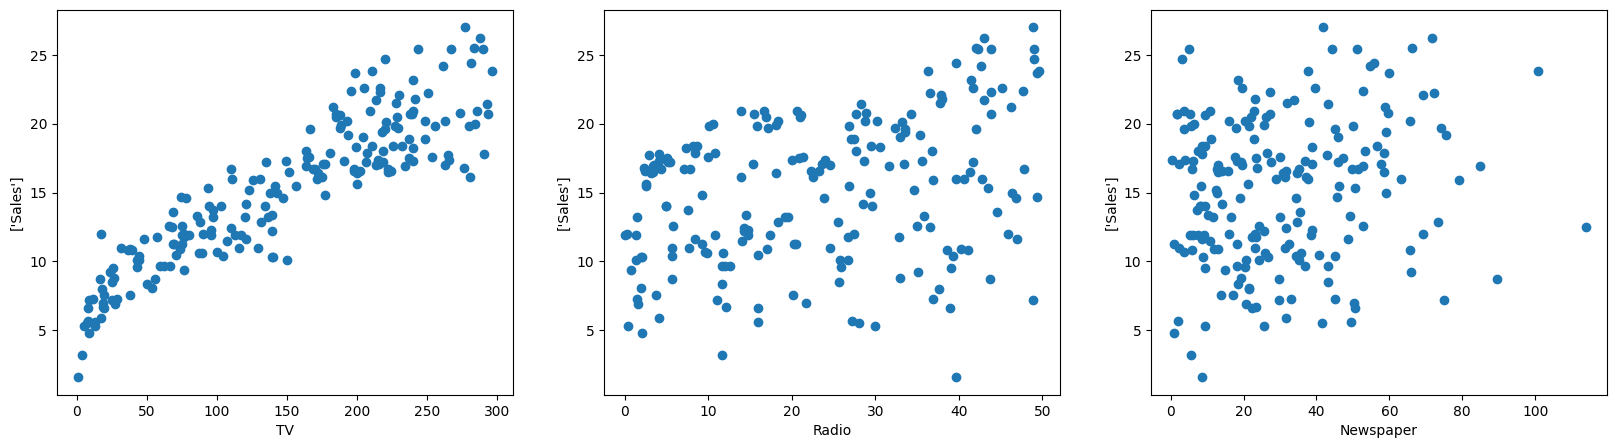

In [13]:
plt.figure(figsize=(20,5))
features = ['TV','Radio','Newspaper']
target = ['Sales']
for i , feature in enumerate(features):
    plt.subplot(1,len(features),i+1)
    plt.scatter(df[feature],df[target])
    plt.xlabel(feature)
    plt.ylabel(target)
plt.ticklabel_format()
plt.show()


## Inferance:
- relationship between feature TV vs Target is Linear 
-  Also with series overall its linear
- but for newspaper data points are randomly spread.

## 2. **Multicollinearity**

In [5]:
# Method 1>>>>
x.corr()

,TV,Radio,Newspaper
TV,1.000000,0.054809,0.056648
Radio,0.054809,1.000000,0.354104
Newspaper,0.056648,0.354104,1.000000


In [6]:
# Method 2>>>
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_df = pd.DataFrame()
vif_df['Features'] = x.columns
vif_df['VIF'] = [variance_inflation_factor(x.values,i) for i in range(x.shape[1])]
print("Varience Inflaction Factor")
vif_df

Varience Inflaction Factor


,Features,VIF
0,TV,2.486772
1,Radio,3.285462
2,Newspaper,3.055245


# **Inferance:**
- There is No multicolinearity exists between Features

## **Split Data**

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
x_train, x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [9]:
x_train.shape,y_train.shape,x_test.shape,y_test.shape

((160, 3), (160,), (40, 3), (40,))

In [10]:
mlr_model = LinearRegression()
mlr_model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [11]:
y_pred = mlr_model.predict(x_test)

## **Model Evaluation Technique**

In [16]:
# R Square:
from sklearn.metrics import  r2_score

In [17]:
r2_score = r2_score(y_test,y_pred)
print('R-Square: ',r2_score)

R-Square:  0.9059011844150826


# **Inferance:**
<button>Our model explaines 90% of varience in target variable</button>

In [20]:
# RMSE:
from sklearn.metrics  import root_mean_squared_error
print("RMSE: ",root_mean_squared_error(y_test,y_pred))


RMSE:  1.7052146229349223


In [21]:
# mse:
from sklearn.metrics import mean_squared_error
print("MSE: ",mean_squared_error(y_test,y_pred))

MSE:  2.9077569102710896


# **Inferance**<br>
<button>mse=2.90,on average are 2.90 units off actual values.</button>

# **Residual**

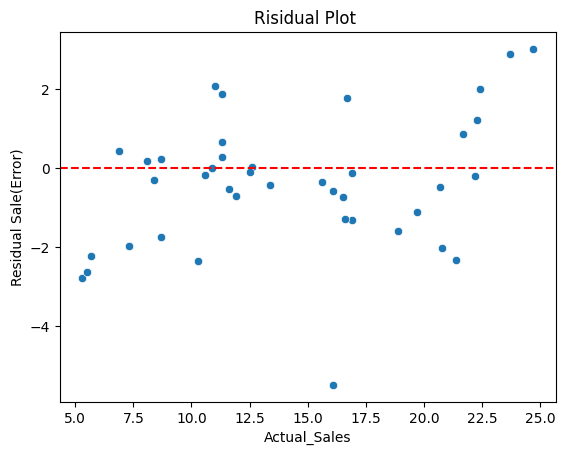

In [23]:
residual = y_test-y_pred
import seaborn as sns
sns.scatterplot(x= y_test,y=residual)
plt.axhline(linestyle='--',color = 'red')
plt.xlabel("Actual_Sales")
plt.ylabel("Residual Sale(Error)")
plt.title("Risidual Plot ")
plt.show()

# **Inferance:**
There is no clear pattern, that,s good